# 02b · iNaturalist vs. lydemapr Survey Data

**Question:** Do iNaturalist sightings track actual lanternfly population levels? If they do, iNaturalist counts are a usable response for predicting population numbers; if not, we need to know where and how they fail.

**Reference data:** [lydemapr](https://github.com/ieco-lab/lydemapr) (Zenodo 7976229), compiled US lanternfly records for 2014–2021. We keep only **field surveys** by the PA Dept. of Agriculture, other state agencies and USDA, because they:
- record **absences** (surveyed sites with no lanternflies), and
- record **density** on an ordinal scale: Unpopulated < Low (≤~30 individuals or 1 egg mass) < Medium (countable, up to a few hundred) < High (too many to count).

lydemapr's own iNaturalist rows are dropped, and so are public-hotline reports, which share iNaturalist's reporting bias. That keeps the comparison independent.

**Unit:** county × calendar year, 2014–2021.

*Code generated w/ help from Claude Code* See `docs/ai_usage.md` for how it was checked.

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import data_sources as ds

YEARS = list(range(2014, 2022))   # lydemapr coverage
MIN_SURVEYS = 10                  # survey points needed for a county-year's density estimate
counties = ds.load_counties()

## 1. Survey data: county-year density

In [2]:
lyde = ds.load_lyde()
survey = lyde[(lyde["collection_method"] == "field_survey/management") & lyde["year"].isin(YEARS)].copy()
print(f"{len(lyde):,} lydemapr records → {len(survey):,} field-survey records in {YEARS[0]}–{YEARS[-1]}")

survey = ds.assign_county(survey, counties)
print(f"Outside any county: {survey['fips'].isna().mean():.2%}")
survey["density_score"] = survey["lyde_density"].cat.codes      # 0 = Unpopulated … 3 = High
# Plain floats (missing establishment → NaN, skipped by the means below)
survey["present_f"] = survey["lyde_present"].astype(float)
survey["established_f"] = survey["lyde_established"].astype("Float64").astype(float)

sv = (survey.dropna(subset=["fips"])
            .groupby(["fips", "year"])
            .agg(n_surveys=("pointID", "size"),
                 share_present=("present_f", "mean"),
                 share_established=("established_f", "mean"),
                 mean_density=("density_score", "mean"),
                 share_high=("density_score", lambda s: (s == 3).mean()))
            .reset_index())
sv = sv[sv["n_surveys"] >= MIN_SURVEYS]
print(f"County-years with ≥{MIN_SURVEYS} survey points: {len(sv):,} across {sv['fips'].nunique()} counties")
sv.describe().round(3)

658,390 lydemapr records → 377,829 field-survey records in 2014–2021
Outside any county: 0.18%
County-years with ≥10 survey points: 959 across 378 counties


,year,n_surveys,share_present,share_established,mean_density,share_high
count,959.000,959.000,959.000,959.000,959.000,959.000
mean,2019.200,390.922,0.083,0.043,0.060,0.003
std,1.662,1028.974,0.199,0.117,0.178,0.016
min,2014.000,10.000,0.000,0.000,0.000,0.000
25%,2018.000,25.000,0.000,0.000,0.000,0.000
50%,2019.000,73.000,0.000,0.000,0.000,0.000
75%,2021.000,301.500,0.041,0.009,0.009,0.000
max,2021.000,13865.000,1.000,1.000,1.700,0.353


In [3]:
print("Surveyed county-years by state (top 12):")
sv.merge(counties[["fips", "state"]], on="fips")["state"].value_counts().head(12)

Surveyed county-years by state (top 12):


state
PA    397
VA    154
NY    133
NJ     69
NC     55
MD     38
WV     34
MA     13
CT     11
DE     11
OH     11
IN      8
Name: count, dtype: int64

**Caveat:** field surveys aren't random. Agencies target known or suspected infestations and high-risk sites, so survey shares describe *surveyed sites*, not the whole county. We use them to **rank** county-years by population level, not as unbiased county-wide estimates.

## 2. Join iNaturalist to the surveyed county-years

In [4]:
# Raw iNaturalist API sightings (all licenses) per county-year
inat = pd.read_parquet(ds.PROCESSED / "inat_slf_with_county.parquet")
inat_cy = (inat.dropna(subset=["fips"]).assign(year=lambda d: d["observed_on"].dt.year)
               .groupby(["fips", "year"]).size().rename("inat_slf").reset_index())

# GBIF effort and lanternfly counts (same open-license subset, for rates)
eff = pd.read_parquet(ds.PROCESSED / "county_year_effort.parquet")[["fips", "year", "all_obs", "slf_obs"]]
eff = pd.concat([eff, ds.fetch_gbif_county_counts([2014]).rename(columns={"n_obs": "all_obs"})
                     .merge(ds.fetch_gbif_county_counts([2014], taxon_key=ds.GBIF_SLF_TAXON_KEY)
                              .rename(columns={"n_obs": "slf_obs"}), on=["fips", "year"], how="left")]
                ).drop_duplicates(["fips", "year"])

cmp_ = (sv.merge(inat_cy, on=["fips", "year"], how="left")
          .merge(eff, on=["fips", "year"], how="left")
          .fillna({"inat_slf": 0, "slf_obs": 0, "all_obs": 0})
          .merge(counties[["fips", "state", "county"]], on="fips"))
cmp_["log_inat"] = np.log1p(cmp_["inat_slf"])
cmp_["slf_per_10k"] = np.where(cmp_["all_obs"] > 0, 1e4 * cmp_["slf_obs"] / cmp_["all_obs"].clip(lower=1), np.nan)
print(cmp_.shape)
cmp_[["n_surveys", "share_established", "mean_density", "inat_slf", "all_obs", "slf_per_10k"]].describe().round(2)

taxon5157899 2014: 0 observations
(959, 14)


,n_surveys,share_established,mean_density,inat_slf,all_obs
count,959.00,959.00,959.00,959.00,959.00
mean,390.92,0.04,0.06,11.94,2889.47
std,1028.97,0.12,0.18,50.33,5835.04
min,10.00,0.00,0.00,0.00,0.00
25%,25.00,0.00,0.00,0.00,265.00
50%,73.00,0.00,0.00,0.00,885.00
75%,301.50,0.01,0.01,0.00,2579.50
max,13865.00,1.00,1.70,509.00,61829.00


## 3. Detection: when surveys find an established population, does iNaturalist see it?

A county-year counts as *established* if at least 5% of its survey points are established. This is a low bar, chosen to flag real populations rather than one-off finds.

Established county-years: 159; detected by iNaturalist (≥1 sighting): 75%
Not-established county-years with ≥1 iNaturalist sighting: 12% (n = 800)


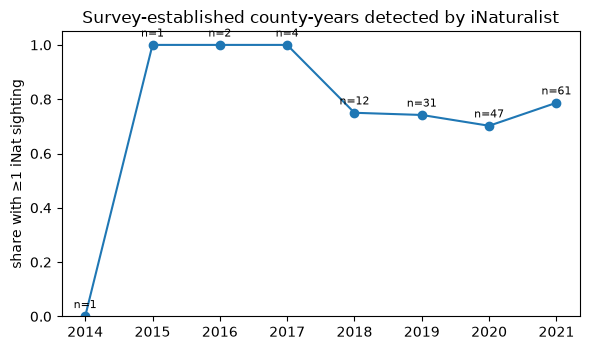

In [5]:
cmp_["survey_established"] = cmp_["share_established"] >= 0.05
est = cmp_[cmp_["survey_established"]]
det = est.groupby("year").agg(n=("fips", "size"), inat_detected=("inat_slf", lambda s: (s > 0).mean()))
print(f"Established county-years: {len(est):,}; detected by iNaturalist (≥1 sighting): {(est['inat_slf'] > 0).mean():.0%}")

# The other direction: iNaturalist sightings in county-years surveys call unestablished
fp = cmp_[~cmp_["survey_established"]]
print(f"Not-established county-years with ≥1 iNaturalist sighting: {(fp['inat_slf'] > 0).mean():.0%} (n = {len(fp):,})")

fig, ax = plt.subplots(figsize=(6, 3.6))
det["inat_detected"].plot(ax=ax, marker="o")
for y, r in det.iterrows(): ax.annotate(f"n={r['n']:.0f}", (y, r["inat_detected"]), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
ax.set(ylim=(0, 1.05), ylabel="share with ≥1 iNat sighting", xlabel="",
       title="Survey-established county-years detected by iNaturalist")
plt.tight_layout()

## 4. Magnitude: do higher iNaturalist numbers mean denser populations?

In [6]:
def rho(d, x, y):
    d = d[[x, y]].dropna()
    r, p = spearmanr(d[x].to_numpy(float), d[y].to_numpy(float))
    return pd.Series({"spearman_rho": r, "p_value": p, "n": len(d)})

pairs = [(x, y) for y in ["mean_density", "share_established"] for x in ["log_inat", "slf_per_10k"]]
tbl = pd.DataFrame({f"{x} vs {y}": rho(cmp_, x, y) for x, y in pairs}).T
tbl_inv = pd.DataFrame({f"{x} vs {y}": rho(est, x, y) for x, y in pairs}).T
print("All surveyed county-years:"); display(tbl.round(3))
print("Only survey-established county-years (is there signal in *how many*, not just *whether*?):"); display(tbl_inv.round(3))

All surveyed county-years:


,spearman_rho,p_value,n
log_inat vs mean_density,0.694,0.0,959.0
slf_per_10k vs mean_density,0.692,0.0,956.0
log_inat vs share_established,0.691,0.0,959.0
slf_per_10k vs share_established,0.688,0.0,956.0


Only survey-established county-years (is there signal in *how many*, not just *whether*?):


,spearman_rho,p_value,n
log_inat vs mean_density,0.456,0.0,159.0
slf_per_10k vs mean_density,0.472,0.0,158.0
log_inat vs share_established,0.377,0.0,159.0
slf_per_10k vs share_established,0.378,0.0,158.0


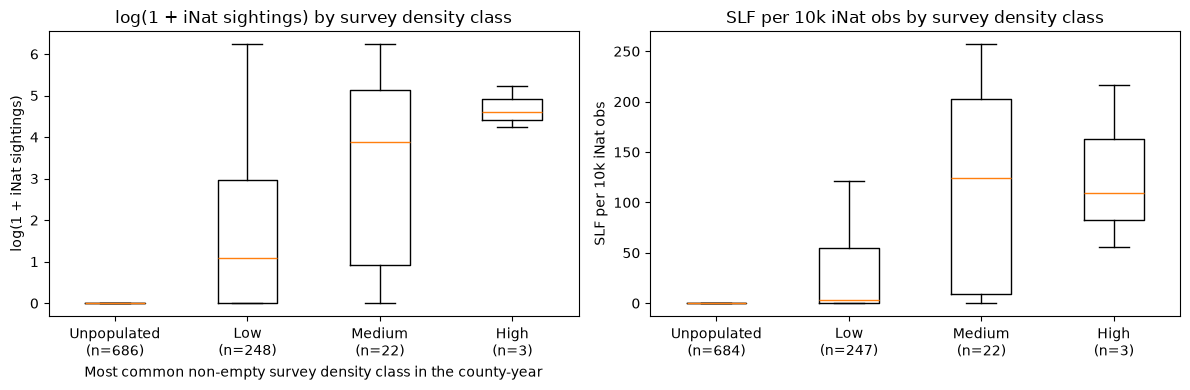

In [7]:
# iNaturalist numbers by the most common survey density class in each county-year
modal = (survey.dropna(subset=["fips"]).groupby(["fips", "year"])["lyde_density"]
               .agg(lambda s: s[s != "Unpopulated"].mode().iloc[0] if (s != "Unpopulated").any() else "Unpopulated")
               .rename("top_density").reset_index())
c2 = cmp_.merge(modal, on=["fips", "year"])
c2["top_density"] = pd.Categorical(c2["top_density"], categories=ds.LYDE_DENSITY, ordered=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col, lab in [(ax[0], "log_inat", "log(1 + iNat sightings)"), (ax[1], "slf_per_10k", "SLF per 10k iNat obs")]:
    groups = [c2.loc[c2["top_density"] == k, col].dropna() for k in ds.LYDE_DENSITY]
    a.boxplot(groups, tick_labels=[f"{k}\n(n={len(g)})" for k, g in zip(ds.LYDE_DENSITY, groups)], showfliers=False)
    a.set(ylabel=lab, title=f"{lab} by survey density class")
ax[0].set_xlabel("Most common non-empty survey density class in the county-year")
plt.tight_layout()

## 5. Does iNaturalist carry population information beyond effort?

If iNaturalist counts only reflect how many people are looking, survey density adds nothing once effort is known. Compare OLS fits of `log(1 + iNat sightings)`:

In [8]:
import statsmodels.formula.api as smf

d = cmp_[cmp_["all_obs"] > 0].assign(log_effort=lambda x: np.log(x["all_obs"]))
m0 = smf.ols("log_inat ~ log_effort + C(year)", d).fit()
m1 = smf.ols("log_inat ~ log_effort + C(year) + mean_density", d).fit()
print(f"n = {len(d):,}")
print(f"effort + year:           R² = {m0.rsquared:.3f}")
print(f"+ survey mean density:   R² = {m1.rsquared:.3f}  (density coef = {m1.params['mean_density']:.2f}, "
      f"95% CI {m1.conf_int().loc['mean_density', 0]:.2f} to {m1.conf_int().loc['mean_density', 1]:.2f})")
print(f"F-test for adding density: p = {m1.compare_f_test(m0)[1]:.2g}")

n = 956
effort + year:           R² = 0.149
+ survey mean density:   R² = 0.453  (density coef = 4.29, 95% CI 3.92 to 4.65)
F-test for adding density: p = 7.3e-93


## 6. Timing: how far behind surveys is iNaturalist?

For counties where surveys found an established population, compare the first year surveys detected establishment with the first year of any iNaturalist sighting.

Counties with survey-detected establishment: 76; never seen on iNaturalist: 0
count    76.00
mean      0.21
std       1.63
min      -8.00
25%       0.00
50%       0.00
75%       1.00
max       4.00
Name: inat_lag_years, dtype: float64


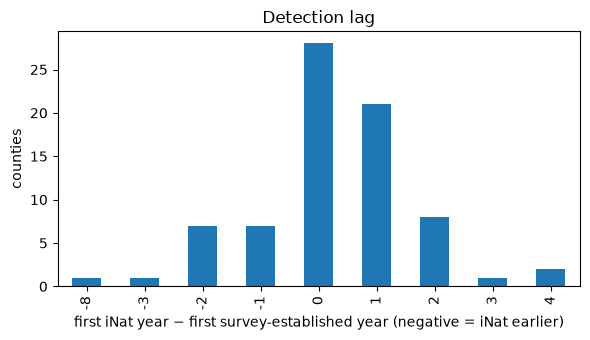

In [9]:
first_survey = est.groupby("fips")["year"].min().rename("first_survey_est")
first_inat = inat_cy.groupby("fips")["year"].min().rename("first_inat")
lag = pd.concat([first_survey, first_inat], axis=1).dropna(subset=["first_survey_est"])
lag["inat_lag_years"] = lag["first_inat"] - lag["first_survey_est"]

print(f"Counties with survey-detected establishment: {len(lag)}; never seen on iNaturalist: {lag['first_inat'].isna().sum()}")
print(lag["inat_lag_years"].describe().round(2))
fig, ax = plt.subplots(figsize=(6, 3.5))
lag["inat_lag_years"].dropna().astype(int).value_counts().sort_index().plot.bar(ax=ax)
ax.set(xlabel="first iNat year − first survey-established year (negative = iNat earlier)", ylabel="counties",
       title="Detection lag")
plt.tight_layout()

### Team interpretation
ToDo
- How often does iNaturalist miss established populations, and does that change as iNaturalist use grows?
- Do higher iNaturalist numbers correspond to denser populations, or only to presence?
- Is survey density still informative once effort is accounted for (section 5)?
- **Decision:** is an iNaturalist-based count a defensible response for predicting population numbers? Should survey data be the response for 2014–2021, or a validation set?

In [10]:
cmp_.to_parquet(ds.PROCESSED / "county_year_inat_vs_survey.parquet", index=False)